In [1]:
# Import the relevant libraries
import numpy as np
import matplotlib.pyplot as plt
import spectral_analysis
from astropy.io import fits
from astropy.io import ascii
from configparser import ConfigParser

In [2]:
def azimuthal_average(power):

    '''
    Purpose
    -------
    Azimuthally average the 3D solar oscillation power spectrum.

    Inputs
    ------
    [power: np.array, float]:
        3D power spectrum to be azimuthally averaged.

    Outputs
    -------
    [azi_avg_power: np.array, float]:
        Azimuthally averaged power (1st quadrant only).

    Author(s)
    ---------
    Julio M. Morales, October 10, 2022
    '''

    # Set up a meshgrid of radii
    x = np.linspace(0, int(power.shape[2]) - 1, int(power.shape[2]))
    y = np.linspace(0, int(power.shape[1]) - 1, int(power.shape[1]))

    # Extract midopints
    xmid, ymid = int(power.shape[2]/2), int(power.shape[1]/2)
    xx, yy = np.meshgrid(x, y)

    # Define empty list of power array
    avg_power_array = []

    # Loop through all of the slices through temporal frequency
    for freq in range(int(power.shape[0]/2), int(power.shape[0])):

        # Take slice
        freq_slice = power[freq, :, :,]

        # Empty power list to be added to
        avg_power = []

        # Start loop
        for i in range(0, int(power.shape[1]/2)):

            # Create a hypotenuse
            d = np.hypot(xx - xmid, yy - ymid)

            # Create mask
            d[np.where((d >= i - 0.5) & (d < i + 0.5))] = 1; d[np.where(d != 1)] = 0

            # NOTE: This method produces a ring of pixels around the center pixel.  The following conditional is to remnedy this
            if (i == 1):
                pass

            else:
                d[int(d.shape[1]/2 + 1), int(d.shape[0]/2)] = d[int(d.shape[1]/2 - 1), int(d.shape[0]/2)] = d[int(d.shape[1]/2), int(d.shape[0]/2 + 1)] = d[int(d.shape[1]/2), int(d.shape[0]/2 - 1)] = 0

            # Apply mask
            masked_image = freq_slice*d

            # Take the average pixel value of the image
            avg_pix = np.nanmean(masked_image)

            # Averaged power
            avg_power.append(avg_pix)

        # Convert list to an array and add to larger array
        avg_power_array.append(np.array(avg_power))

    # Turn list into array
    azi_avg_power = np.array(avg_power_array)

    return np.flipud(azi_avg_power)

In [3]:
# Path to data
path = '/Users/juliomorales/Library/CloudStorage/GoogleDrive-juliomorales1823@gmail.com/My Drive/Graduate School/Research/Projects/Helioseismology/Vesa_2024/Data/'

# Dataset -- 25Apr2019, 26Apr2019, 06May2019, 08May2019, 09May2019
date = "04252019"
written_date = "25Apr2019"
# Model atmosphere of the Sun
model_atm_data = ascii.read(path + "CSM_A.dat")

# Determine which file type to grab -- intensity versus velocity
fname_type_dict = {0: "int", 1: "vel"}
fname_type = fname_type_dict.get(1)

# Choose spectral diagnostics -- HMIcont, HMIdop, fe7090, k7699, fe5434, ca8542 -- all [km/s]
spectral_line_higher = "k7699" # line that forms "higher" in the atmosphere
spectral_line_lower = "fe7090" # line that forms "lower" in the atmosphere

# File names
magnetogram_file = path + written_date + '/' + "%s.HMImag.ibis.aligned.fits"%(written_date)
higher_line_file = path + written_date + '/' + "%s.ibis.to.hmi.%s.%s.fits"%(written_date,fname_type,spectral_line_higher)

if spectral_line_lower == "HMIdop":
    lower_line_file = (
        path + written_date + '/' + "%s.%s.ibis.aligned.fits"%(written_date,spectral_line_lower)
    )
else:
    lower_line_file = path + written_date + '/' + "%s.ibis.to.hmi.%s.%s.fits"%(written_date,fname_type,spectral_line_lower)


# Spectral Line 1
if spectral_line_lower == "HMIdop":
    # HMIdop -- need to multiply by 1e-4 to get [km/s]
    lower_line = fits.open(lower_line_file)[0].data * 1e-4
else:
    lower_line = fits.open(lower_line_file)[0].data

lower_line = np.transpose(lower_line, (1, 2, 0))
# lower_line = np.diff(lower_line,axis=-1)
lower_line -= np.mean(lower_line)

# Spectral Line 2
higher_line = fits.open(higher_line_file)[0].data
higher_line = np.transpose(higher_line, (1, 2, 0))
higher_line -= np.mean(higher_line)

# Config file holds information for each dataset
config_object = ConfigParser()
config_object.read("AGWs_config.ini")

# Dataset -- 25Apr2019, 26Apr2019, 06May2019, 08May2019, 09May2019
date = "04252019"
written_date = "25Apr2019"

# Grab the location and plate scale information associated with chosen date
date_image_information = config_object[date]


distance = 147.1e6  # Earth-Sun distance in km
convert_arcseconds_to_Mm = spectral_analysis.conversion_arcseconds_to_Mm(distance) # scaling for arcsec into Mm


###############################################################################
############################ Grid Information #################################
###############################################################################

distance = 147.1e6  # Earth-Sun distance in km
convert_arcseconds_to_Mm = spectral_analysis.conversion_arcseconds_to_Mm(distance) # scaling for arcsec into Mm

# Spatial sampling [arcsec/pixel]
dx = float(date_image_information["dx"])

# Cadence of data [s]
dt = float(date_image_information["dt"])  

# Nyquist wavenumber [1/arcsec]
kx = np.pi / dx

print("Nyquist wavnumber is %s 1/arcsec" % kx)
print("Nyquist wavnumber is %s 1/Mm" % (kx / convert_arcseconds_to_Mm))
print("Nyquist wavnumber is %s 1/km" % ((kx / convert_arcseconds_to_Mm) / 1000))

# Nyquist frequency/angular frequency [rad/s]
omega = np.pi / dt

# Nyquist frequency/cyclic frequency [Hz]
v = omega / (2 * np.pi)
frq = v * 1000  # [mHz]
print("Nyquist frequency is %s mHz" % frq)

###############################################################################
############################ Define Meshgrid ##################################
###############################################################################

# Starting time
start = 0

# Duration of data -- length of time series
end_time = higher_line.shape[-1]
# Spatial length of data -- x and y... Ideally should be the same value (crop data cube if not)
end_space = higher_line.shape[0]

# Mid time and space
mid_time = end_time // 2
mid_space = end_space // 2

print("The middle time is %s and the end time is %s " % (mid_time, end_time))

# Field of view [arcsec]
fov = dx * end_space 
print("FOV is %s arcseconds" % (fov))

# Horizontal wavenumber 
horizontal_array = np.linspace(0.0, kx, int(mid_space), endpoint=True)  # [1/arcsec]
kx_km = horizontal_array / convert_arcseconds_to_Mm / 1000  # [1/km]

# Field of view array
arcsecond_length_array = np.linspace(0.0, fov, int(end_space), endpoint=True)
# Meshgrid for field of view (if needed)
arcx, arcy = np.meshgrid(arcsecond_length_array, arcsecond_length_array)

print("The FOV meshgrid has the following shape: ", arcx.shape)

# Frequency [mHz]
freq_array = np.linspace(0.0, frq, int(mid_time), endpoint=True)
print("The three first frequencies are ", freq_array[0:4])
print("The length of the frequency array is", len(freq_array))

# Meshgrid for data
NU, KH = np.meshgrid(freq_array, horizontal_array)
print("The meshgrid has the following shape: ", KH.shape)

# Compute grid to azimuthally average over
x = np.linspace(-mid_space, mid_space - 1, end_space)  # size of kx
y = np.linspace(-mid_space, mid_space - 1, end_space)  # sixe of ky
X, Y = np.meshgrid(x, y)
radial_dist = np.hypot(X, Y)
print(
    "The shape of the grid to compute the azimuthal averaging over is ",
    radial_dist.shape,
)

Nyquist wavnumber is 5.235987755982989 1/arcsec
Nyquist wavnumber is 7.341944255608431 1/Mm
Nyquist wavnumber is 0.0073419442556084315 1/km
Nyquist frequency is 42.08754208754208 mHz
The middle time is 420 and the end time is 840 
FOV is 96.0 arcseconds
The FOV meshgrid has the following shape:  (160, 160)
The three first frequencies are  [0.         0.10044759 0.20089519 0.30134278]
The length of the frequency array is 420
The meshgrid has the following shape:  (80, 420)
The shape of the grid to compute the azimuthal averaging over is  (160, 160)


# Phase Difference Tests
The first test I execute is one where I take two cubes of ones and apply a phase difference to the second and calculate their phase difference.  If I do this correctly, I should get the phase difference I applied ($\pi$).

# Notes
* Add the sine curve to every pixel.  Not randoml;y dfistrivuted.
* Use real values for the omega.  0.1 - 3 mHz.
* In the lower height, for each pixel, apply a given frequency and the phase difference.
* In the upper height, apply the same frequency that corresponds to the similar pixel of the first image plus the phase difference.

In [21]:
import random

# Load the magnetogram
magnetogram, mag_header = fits.getdata(path + '25Apr2019/25Apr2019.HMImag.ibis.aligned.fits', header = True)
dopplergram, dop_header = fits.getdata(path + '25Apr2019/25Apr2019.ibis.to.hmi.vel.k7699.fits', header = True)

# Extract shape of magnetogram
nx = mag_header['NAXIS1']
ny = mag_header['NAXIS2']
nt = mag_header['NAXIS3']

# Convert units
magnetogram = magnetogram/10 # Gauss

# Mask value for magnetogram
mask_val = 4.5 # Gauss

# Mask the magnetogram
magnetogram[np.logical_or(magnetogram >= mask_val, magnetogram <= -mask_val)] = np.nan

# Create mask
mask = magnetogram/magnetogram

# Turn mask into ones and zeros
mask[np.where(mask != 1.0)] = 0.0

# Construct arrays
ones_array = np.ones((nt, ny, nx))
phase_array = np.ones((nt, ny, nx))

# Set up the phase difference
n = 1
phase = np.pi/n

# Construct time array
t = np.linspace(0, 30330, nt)

# Loop through the spatial dimensions
for i in range(0, nx):

    for j in range(0, ny):

        # Select temporal frequency
        g = random.uniform(0.1, 3)
        omega = g*2*np.pi/1000 # Hz

        # Set up sine curve
        sine_curve = np.sin(omega*t)
        phase_curve = np.sin(omega*t - phase)

        # Apply sine curve
        ones_array[:, j, i] *= sine_curve
        phase_array[:, j, i] *= phase_curve

/var/folders/p5/s6c93d_s38j4sy11sd_js3s40000gn/T/ipykernel_2013/450223525.py:22: RuntimeWarning: invalid value encountered in divide
  mask = magnetogram/magnetogram


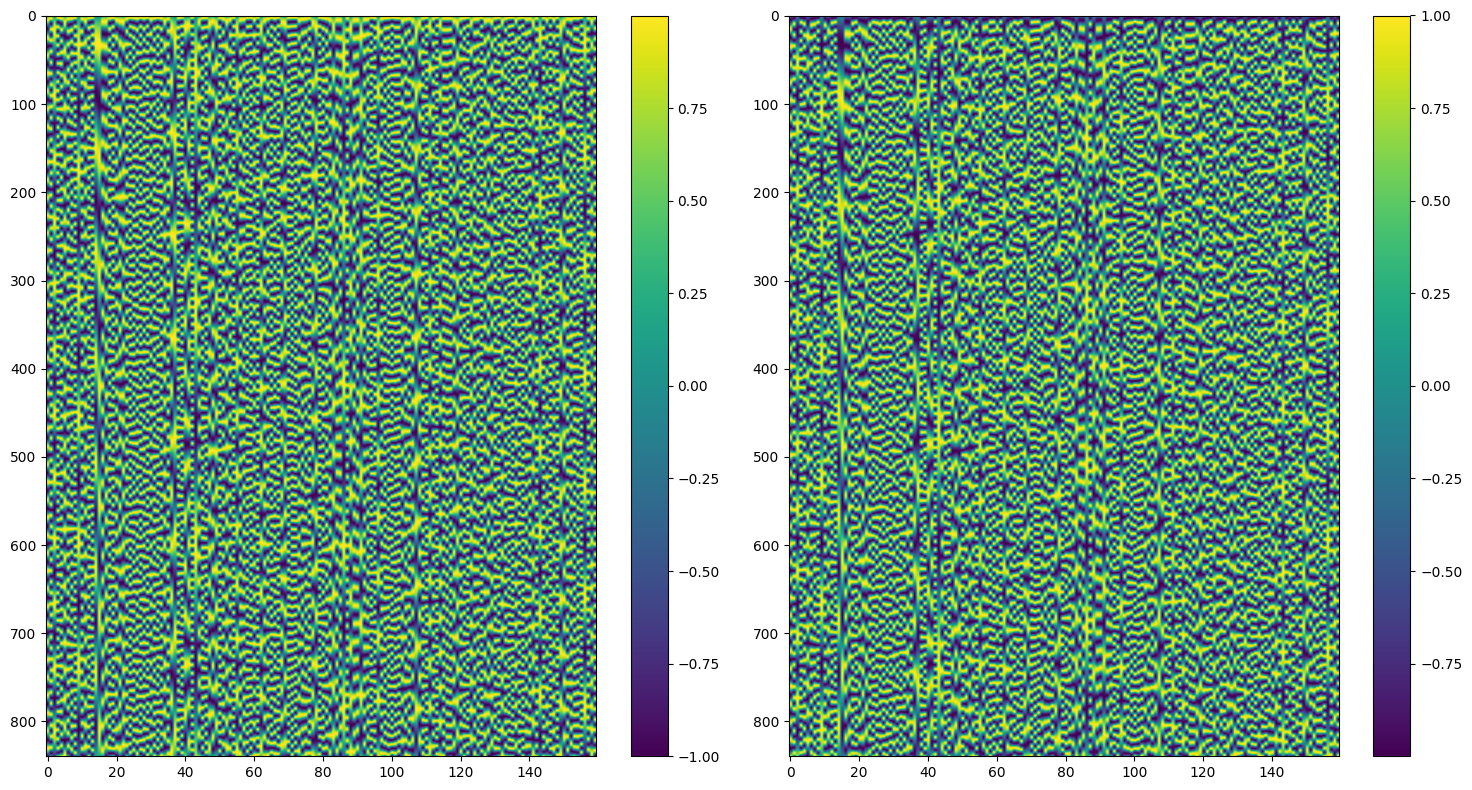

In [22]:
# Side by side comparison
plt.figure(figsize = (15, 8))
plt.subplot(1, 2, 1)
plt.imshow(ones_array[:, 0, :], aspect='auto')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(phase_array[:, 0, :], aspect='auto')
plt.colorbar()
plt.tight_layout()
plt.show()

In [23]:
fft_ones = np.fft.fftn(ones_array)
fft_ones_shift = np.fft.fftshift(fft_ones)

fft_phase = np.fft.fftn(phase_array)
fft_phase_shift = np.fft.fftshift(fft_phase)

ff = fft_ones_shift*np.conj(fft_phase_shift)

ff2d = azimuthal_average(ff)

ff_ang = ff2d

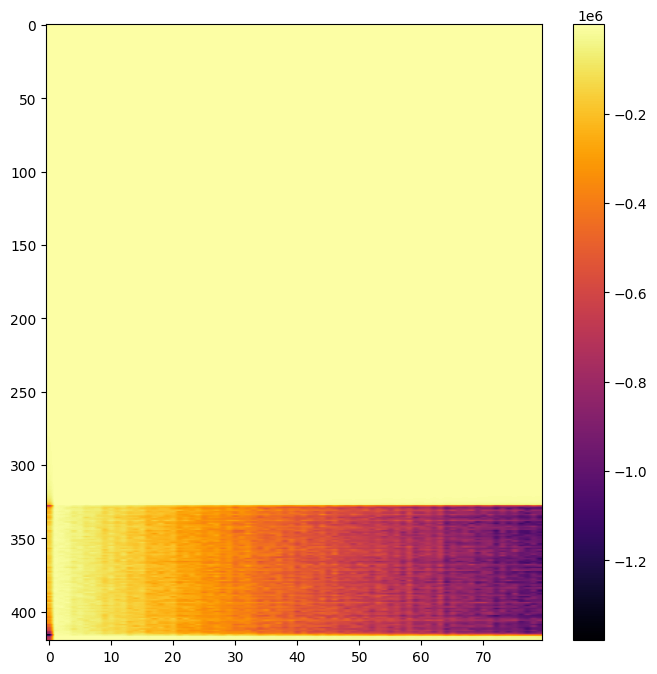

In [25]:
plt.figure(figsize = (8, 8))
plt.imshow(np.real(ff_ang), cmap = 'inferno', aspect = 'auto')
plt.colorbar()
plt.show()